# $\zeta(2)+\zeta(3)$: historical construction and new trajectory

The CMF examples sample every 10 depths through depth 3000.
Each example prints its final $\delta_N$; the figure at the end plots
$\delta_N$ against $N$, where
$$D_N=-\log_{10}\left|\zeta(2)+\zeta(3)-\frac{p_N}{q_N}\right|,
\qquad \delta_N=\frac{D_N}{\log_{10}q_N}-1.$$
Here $p_N/q_N$ is reduced. Accuracy digits measure absolute approximation error.

Run the cells in order (Python 3.11+). The finite-depth $\delta_N$ values are
numerical estimates, not proved limiting exponents.

In [1]:
# @title Install dependencies (run once per environment)
%pip -q install ramanujantools==0.0.8 sympy==1.14.0 matplotlib==3.11.2

## Setup

Each example constructs a CMF, walks a trajectory with ramanujantools, reads
$p_N/q_N$ off the first column $(s_0,s_1,\ldots)$ of the walk, and computes
$\delta_N$. The walks and the approximants are exact.

In [2]:
import sys

import matplotlib.pyplot as plt
import sympy as sp
from flint import arb, ctx
from ramanujantools.cmf.pfq import pFq

sys.set_int_max_str_digits(0)
with ctx.workdps(230_000):  # q_N reaches about 110,000 digits at depth 3000
    ZETA23 = arb(2).zeta() + arb(3).zeta()
DEPTHS = list(range(10, 3001, 10))
x0, x1, x2, x3, y0, y1, y2 = sp.symbols("x0 x1 x2 x3 y0 y1 y2")
results = {}


def delta(approximant):
    """delta with |ζ(2) + ζ(3) - p/q| = q^-(1 + delta), for the reduced fraction p/q."""
    p, q = int(approximant.p), int(approximant.q)
    with ctx.workprec(2 * q.bit_length() + 64):  # enough bits to resolve |ζ(2) + ζ(3) - p/q|
        error = abs(ZETA23 - arb(p) / q)
    return float((-1 - error.log() / arb(q).log()).mid())

## 1. Dauguet–Zudilin (2014)

S. Dauguet and W. Zudilin, *On simultaneous diophantine approximations to
$\zeta(2)$ and $\zeta(3)$*, J. Number Theory **145** (2014), 362–387.
[Paper](https://doi.org/10.1016/j.jnt.2014.06.007).
The trajectory encodes their Eq. (27). The paper constructs simultaneous
approximations to $\zeta(2)$ and $\zeta(3)$; it does not assert an exponent
for their sum.

**CMF:** ${}_4F_3(1)$ · **Start:** $(1,1,1,0;1,1,1)$ ·
**Direction:** $(10,9,8,-5;3,2,1)$. We use the direct walk and the
extraction $p_N/q_N=s_1/s_0$.

In [3]:
cmf = pFq(4, 3, 1)
start = {x0: 1, x1: 1, x2: 1, x3: 0, y0: 1, y1: 1, y2: 1}
trajectory = {x0: 10, x1: 9, x2: 8, x3: -5, y0: 3, y1: 2, y2: 1}
walks = cmf.walk(trajectory, DEPTHS, start)
approximants = [W[1, 0] / W[0, 0] for W in walks]
deltas = [delta(r) for r in approximants]
results["Dauguet–Zudilin (2014)"] = (DEPTHS, deltas)
print(f"delta at depth 3000: {deltas[-1]:.9f}")

delta at depth 3000: -0.101191465


## 2. New ${}_4F_3(1)$ trajectory

The experimental $\zeta(2)+\zeta(3)$ trajectory of the paper (Appendix B and
the table of search results), with a numerical exponent near $-0.00018$.

**CMF:** ${}_4F_3(1)$ · **Start:** $(7,8,6,9;2,3,16)$ ·
**Direction:** $(11,13,15,16;2,4,30)$. We use the direct walk. With
$c_j=s_j/s_0$, the extraction is $p_N/q_N=N_{2,3}/D_{2,3}$, where
$$\begin{aligned}
N_{2,3}&=320242182383092497c_1-5523372274576928103c_2-18266336406752995,\\
D_{2,3}&=112484439099648000c_1-1940073689296512000c_2-6416014872960000.
\end{aligned}$$

In [4]:
cmf = pFq(4, 3, 1)
start = {x0: 7, x1: 8, x2: 6, x3: 9, y0: 2, y1: 3, y2: 16}
trajectory = {x0: 11, x1: 13, x2: 15, x3: 16, y0: 2, y1: 4, y2: 30}
walks = cmf.walk(trajectory, DEPTHS, start)
approximants = []
for W in walks:
    c1, c2 = W[1, 0] / W[0, 0], W[2, 0] / W[0, 0]
    numerator = 320242182383092497 * c1 - 5523372274576928103 * c2 - 18266336406752995
    denominator = 112484439099648000 * c1 - 1940073689296512000 * c2 - 6416014872960000
    approximants.append(numerator / denominator)
deltas = [delta(r) for r in approximants]
results["New ${}_4F_3(1)$ trajectory"] = (DEPTHS, deltas)
print(f"delta at depth 3000: {deltas[-1]:.9f}")

delta at depth 3000: 0.000107264


## All constructions

$\delta_N$ against the walk depth $N$.

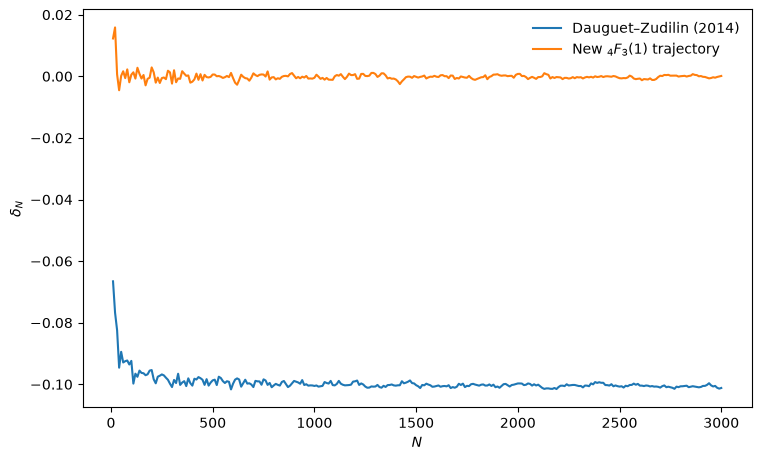

In [5]:
fig, ax = plt.subplots(figsize=(7.5, 4.5), constrained_layout=True)
for name, (depths, values) in results.items():
    ax.plot(depths, values, label=name)
ax.set(xlabel="$N$", ylabel=r"$\delta_N$")
ax.legend(frameon=False)
plt.show()

## Overview

| Construction | Paper's numerical $\delta$ | Notebook coverage |
|:--|--:|:--|
| Dauguet–Zudilin (2014) | $-0.101$ | CMF above |
| This work | $-0.00018$ | CMF above |

Neither row is an irrationality-measure bound: both exponents are negative, and
the irrationality of $\zeta(2)+\zeta(3)$ is open. The new trajectory is the
closest of the search outputs to the threshold $\delta=0$: its finite-depth
$\delta_N$ fluctuates around $0$, and a positive finite-depth value proves nothing.